In [14]:
# pierwsza wartosc to jak czesto to slowa pojawilo sie w ogloszeniu o prace, a druga to jak czesto w resume
data = [ ("big data", 100, 15), ("Hadoop", 95, 25), ("Python", 75, 50),
         ("R", 50, 40), ("machine learning", 80, 20), ("statistics", 20, 60),
         ("data science", 60, 70), ("analytics", 90, 3),
         ("team player", 85, 85), ("dynamic", 2, 90), ("synergies", 70, 0),
         ("actionable insights", 40, 30), ("think out of the box", 45, 10),
         ("self-starter", 30, 50), ("customer focus", 65, 15),
         ("thought leadership", 35, 35)]

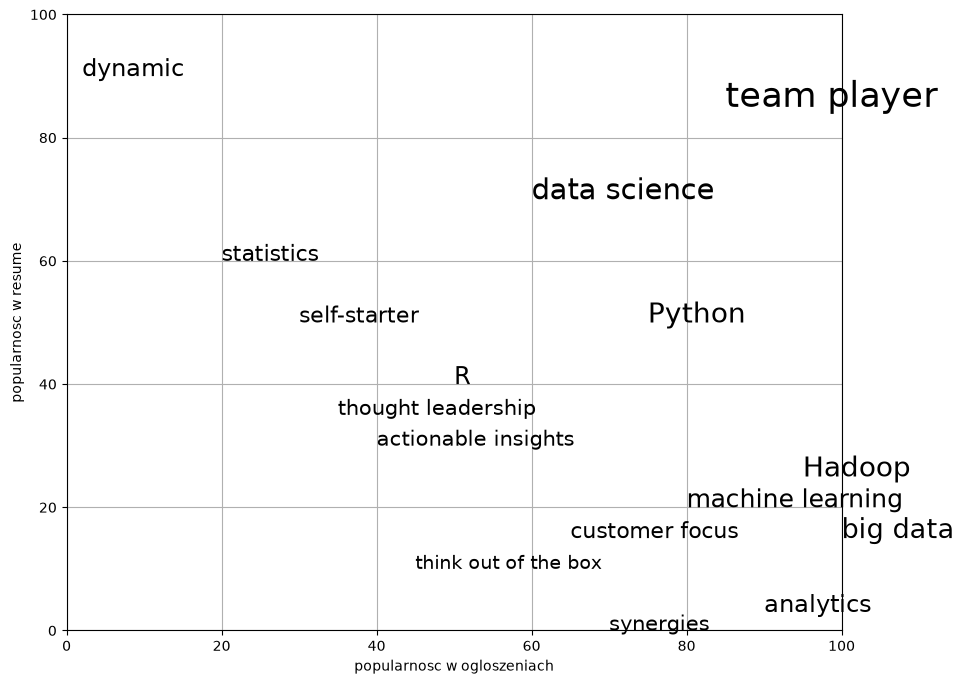

In [15]:
from matplotlib import pyplot as plt

def text_size(total: int) -> float:
    """wielkosc napisu w zaleznosci od sumy jego wystepowania"""
    return (20 / 200) * total + 8

assert text_size(0) == 8 and text_size(200) == 28

plt.figure(figsize=(10, 8))

for word, f_1, f_2 in data:
    plt.text(
        f_1, f_2, 
        word, 
        size=text_size(f_1 + f_2),
    )

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel("popularnosc w ogloszeniach")
plt.ylabel("popularnosc w resume")
plt.grid(True)

plt.show()

In [16]:
import re
from bs4 import BeautifulSoup
import requests

url = "https://www.oreilly.com/ideas/what-is-data-science"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

resp = requests.get(url, headers=headers)
resp.raise_for_status()

soup = BeautifulSoup(resp.text, "html.parser")

def fix_unicode(text: str) -> str:
    return text.replace("\u2019", "'")

# Szukamy kontenera artykułu — bezpieczny fallback na znacznik <article> lub bezpośrednio <body>
content =  soup.body

regex = r"[\w']+|[.]"
document = []

if content:
    for paragraph in content.find_all("p"):
        words = re.findall(regex, fix_unicode(paragraph.text))
        document.extend(words)
else:
    print("Nie znaleziono kontenera z treścią.")
document = document[79:]

In [17]:
from collections import defaultdict

transitions = defaultdict(list)
for prev, current in zip(document, document[1:]):
    transitions[prev].append(current)
list(transitions.items())[0]


("We've", ['all', 'all', 'all'])

In [18]:
import random
def generate_using_bigrams() -> str:
    current = "."   # this means the next word will start a sentence
    result = []
    while True:
        next_word_candidates = transitions[current]    # bigrams (current, _)
        current = random.choice(next_word_candidates)  # choose one at random
        result.append(current)                         # append it to results
        if current == ".": return " ".join(result)     # if "." we're done

bigram_model = [generate_using_bigrams() for _ in range(5)]
bigram_model

["2026 O'Reilly we aren't concerned about testing hypotheses and understanding of public report only part of known data science .",
 'There are consumer equipment fails .',
 "Patil calls data and then distributed across LinkedIn's data but there are then using Google popularized the spread of data visualization itself becomes part of computing time they had huge mountain of data analysis .",
 'If data scientist .',
 "In data is that they aren't ."]

In [19]:
trigram_transitions = defaultdict(list)
starts = []

for prev, current, next in zip(document, document[1:], document[2:]):

    if prev == ".":              # if the previous "word" was a period
        starts.append(current)   # then this is a start word

    trigram_transitions[(prev, current)].append(next)

def generate_using_trigrams() -> str:
    current = random.choice(starts)   # choose a random starting word
    prev = "."                        # and precede it with a '.'
    result = [current]
    while True:
        next_word_candidates = trigram_transitions[(prev, current)]
        next_word = random.choice(next_word_candidates)

        prev, current = current, next_word
        result.append(current)

        if current == ".":
            return " ".join(result)
        
trigram_model = [generate_using_trigrams() for _ in range(5)]
trigram_model

["Whether humans or software decided to ignore anomalous data it appears that data useful The first step of any data analysis is comparative if you're asking whether sales to Southern Europe you aren't concerned about the quality of your retail transactions not just companies using their own data but all the metadata nicely in place .",
 "While that sounds like a simple MapReduce implementation of MapReduce is the grammar of data that's different According to Hilary Mason says that in 1984 they decided that the low values whch went back to other data sources to verify them .",
 'Scientists also know how to use data .',
 'To get a sense of the visualizations are full fledged interactive applications .',
 'They accept all data formats including the most popular courses in computer science to mathematics to art .']

In [20]:
from typing import List, Dict
# Type alias to refer to grammars later
Grammar = Dict[str, List[str]]

grammar = {
    "_S"  : ["_NP _VP"],
    "_NP" : ["_N",
             "_A _NP _P _A _N"],
    "_VP" : ["_V",
             "_V _NP"],
    "_N"  : ["data science", "Python", "regression"],
    "_A"  : ["big", "linear", "logistic"],
    "_P"  : ["about", "near"],
    "_V"  : ["learns", "trains", "tests", "is"]
}

['_S']
['_NP','_VP']
['_N','_VP']
['Python','_VP']
['Python','_V','_NP']
['Python','trains','_NP']
['Python','trains','_A','_NP','_P','_A','_N']
['Python','trains','logistic','_NP','_P','_A','_N']
['Python','trains','logistic','_N','_P','_A','_N']
['Python','trains','logistic','data science','_P','_A','_N']
['Python','trains','logistic','data science','about','_A','_N']
['Python','trains','logistic','data science','about','logistic','_N']
['Python','trains','logistic','data science','about','logistic','Python']

['Python', 'trains', 'logistic', 'data science', 'about', 'logistic', 'Python']

In [21]:
def is_terminal(token: str) -> bool:
    return token[0] != "_"

def expand(grammar: Grammar, tokens: List[str]) -> List[str]:
    for i, token in enumerate(tokens):
        # If this is a terminal token, skip it.
        if is_terminal(token): continue

        # Otherwise, it's a non-terminal token,
        # so we need to choose a replacement at random.
        replacement = random.choice(grammar[token])

        if is_terminal(replacement):
            tokens[i] = replacement
        else:
            # Replacement could be e.g. "_NP _VP", so we need to
            # split it on spaces and splice it in.
            tokens = tokens[:i] + replacement.split() + tokens[(i+1):]

        # Now call expand on the new list of tokens.
        return expand(grammar, tokens)

    # If we get here we had all terminals and are done
    return tokens

In [22]:
def generate_sentence(grammar: Grammar) -> List[str]:
    return expand(grammar, ["_S"])

generate_sentence(grammar)

['big',
 'big',
 'logistic',
 'logistic',
 'logistic',
 'Python',
 'near',
 'big',
 'data science',
 'near',
 'big',
 'data science',
 'near',
 'big',
 'data science',
 'about',
 'logistic',
 'Python',
 'near',
 'logistic',
 'data science',
 'is']

In [23]:
# gibbis sampling
from typing import Tuple
def roll_a_die() -> int:
    return random.choice(list(range(1,7)))
def direct_sample() -> Tuple[int, int]:
    d1 = roll_a_die()
    d2 = roll_a_die()
    return d1, d1 + d2

def randm_y_given_x(x:int) -> int:
    return x + roll_a_die()

def random_x_given_y(y:int) -> int:
    if y <= 7:
        return random.choice(list(range(1,y)))
    else:
        return random.choice(list(range(y-6, 7)))
    
def gibbs_sample (num_iters: int = 100) -> Tuple[int, int]:
    x, y = 1, 2
    for _ in range(num_iters):
        x = random_x_given_y(y)
        y = randm_y_given_x(x)
    return x, y 

def compare_distributions(num_samples: int = 5000) -> Dict[int, List[int]]:
    counts = defaultdict(lambda: [0, 0])
    for _ in range(num_samples):
        counts[gibbs_sample()][0] += 1
        counts[direct_sample()][1] += 1
    return counts
compare_distributions()

defaultdict(<function __main__.compare_distributions.<locals>.<lambda>()>,
            {(3, 4): [107, 122],
             (3, 6): [120, 109],
             (2, 3): [135, 128],
             (2, 4): [150, 153],
             (4, 6): [134, 144],
             (4, 5): [124, 129],
             (1, 4): [137, 138],
             (1, 6): [150, 141],
             (3, 8): [145, 143],
             (2, 5): [125, 126],
             (5, 11): [145, 112],
             (6, 12): [122, 139],
             (4, 8): [147, 145],
             (1, 3): [138, 127],
             (2, 6): [132, 141],
             (2, 7): [141, 139],
             (6, 11): [161, 145],
             (6, 10): [151, 153],
             (6, 8): [137, 145],
             (3, 9): [129, 132],
             (3, 7): [145, 134],
             (2, 8): [165, 148],
             (3, 5): [123, 145],
             (6, 7): [137, 134],
             (1, 7): [131, 148],
             (5, 9): [147, 160],
             (1, 5): [141, 159],
             (5, 6): [124, 124

In [24]:
def sample_from(weights: List[float]) -> int:
    """returns i with probability weights[i] / sum(weights)"""
    total = sum(weights)
    rnd = total * random.random()      # uniform between 0 and total
    for i, w in enumerate(weights):
        rnd -= w                       # return the smallest i such that
        if rnd <= 0: return i          # weights[0] + ... + weights[i] >= rnd

from collections import Counter

# Draw 1000 times and count
draws = Counter(sample_from([0.1, 0.1, 0.8]) for _ in range(1000))
assert 10 < draws[0] < 190   # should be ~10%, this is a really loose test
assert 10 < draws[1] < 190   # should be ~10%, this is a really loose test
assert 650 < draws[2] < 950  # should be ~80%, this is a really loose test
assert draws[0] + draws[1] + draws[2] == 1000

In [25]:
documents = [
    ["Hadoop", "Big Data", "HBase", "Java", "Spark", "Storm", "Cassandra"],
    ["NoSQL", "MongoDB", "Cassandra", "HBase", "Postgres"],
    ["Python", "scikit-learn", "scipy", "numpy", "statsmodels", "pandas"],
    ["R", "Python", "statistics", "regression", "probability"],
    ["machine learning", "regression", "decision trees", "libsvm"],
    ["Python", "R", "Java", "C++", "Haskell", "programming languages"],
    ["statistics", "probability", "mathematics", "theory"],
    ["machine learning", "scikit-learn", "Mahout", "neural networks"],
    ["neural networks", "deep learning", "Big Data", "artificial intelligence"],
    ["Hadoop", "Java", "MapReduce", "Big Data"],
    ["statistics", "R", "statsmodels"],
    ["C++", "deep learning", "artificial intelligence", "probability"],
    ["pandas", "R", "Python"],
    ["databases", "HBase", "Postgres", "MySQL", "MongoDB"],
    ["libsvm", "regression", "support vector machines"]
]

In [26]:
K = 4
document_topic_counts = [Counter() for _ in documents] # rozklad tematow dla kazdego wiersza

topic_word_counts = [Counter() for _ in range(K)] # licznik slowa w temacie

topic_counts = [0 for _ in range(K)] # liczba konkretnego tematu

document_lengths = [len(document) for document in documents] # ilosc slow w wierszu 

distinct_words = set(word for document in documents for word in document) # unikalne slowa
W = len(distinct_words)

D = len(documents)

In [27]:
def p_topic_given_document(topic: int, d: int, alpha: float = 0.1) -> float:
    """
    The fraction of words in document _d_
    that are assigned to _topic_ (plus some smoothing)
    """
    return ((document_topic_counts[d][topic] + alpha) /
            (document_lengths[d] + K * alpha))

def p_word_given_topic(word: str, topic: int, beta: float = 0.1) -> float:
    """
    The fraction of words assigned to _topic_
    that equal _word_ (plus some smoothing)
    """
    return ((topic_word_counts[topic][word] + beta) /
            (topic_counts[topic] + W * beta))

def topic_weight(d: int, word: str, k: int) -> float:
    """
    Given a document and a word in that document,
    return the weight for the kth topic
    """
    return p_word_given_topic(word, k) * p_topic_given_document(k, d)

def choose_new_topic(d: int, word: str) -> int:
    return sample_from([topic_weight(d, word, k)
                        for k in range(K)])

random.seed(0)
document_topics = [[random.randrange(K) for word in document]
                   for document in documents]

for d in range(D):
    for word, topic in zip(documents[d], document_topics[d]):
        document_topic_counts[d][topic] += 1
        topic_word_counts[topic][word] += 1
        topic_counts[topic] += 1

import tqdm

for iter in tqdm.trange(1000):
    for d in range(D):
        for i, (word, topic) in enumerate(zip(documents[d],
                                              document_topics[d])):

            # remove this word / topic from the counts
            # so that it doesn't influence the weights
            document_topic_counts[d][topic] -= 1
            topic_word_counts[topic][word] -= 1
            topic_counts[topic] -= 1
            document_lengths[d] -= 1

            # choose a new topic based on the weights
            new_topic = choose_new_topic(d, word)
            document_topics[d][i] = new_topic

            # and now add it back to the counts
            document_topic_counts[d][new_topic] += 1
            topic_word_counts[new_topic][word] += 1
            topic_counts[new_topic] += 1
            document_lengths[d] += 1

for k, word_counts in enumerate(topic_word_counts):
    for word, count in word_counts.most_common():
        if count > 0:
            print(k, word, count)

100%|██████████| 1000/1000 [00:00<00:00, 10069.37it/s]

0 Java 3
0 Big Data 3
0 Hadoop 2
0 HBase 1
0 C++ 1
0 Spark 1
0 Storm 1
0 programming languages 1
0 MapReduce 1
0 Cassandra 1
0 deep learning 1
1 HBase 2
1 neural networks 2
1 Postgres 2
1 MongoDB 2
1 machine learning 2
1 Cassandra 1
1 numpy 1
1 decision trees 1
1 deep learning 1
1 databases 1
1 MySQL 1
1 NoSQL 1
1 artificial intelligence 1
1 scipy 1
2 regression 3
2 Python 2
2 R 2
2 libsvm 2
2 scikit-learn 2
2 mathematics 1
2 support vector machines 1
2 Haskell 1
2 Mahout 1
3 statistics 3
3 probability 3
3 Python 2
3 R 2
3 pandas 2
3 statsmodels 2
3 C++ 1
3 artificial intelligence 1
3 theory 1


In [28]:
import math
import numpy  as np
def cosine_similarity(v1: list[float], v2: list[float]) -> float:
    return np.dot(v1, v2).item() / math.sqrt(np.dot(v1, v1).item() * np.dot(v2, v2).item())

assert cosine_similarity([1., 1, 1], [2., 2, 2]) == 1, "same direction"
assert cosine_similarity([-1., -1], [2., 2]) == -1,    "opposite direction"
assert cosine_similarity([1., 0], [0., 1]) == 0,       "orthogonal"

In [29]:
colors = ["red", "green", "blue", "yellow", "black", ""]
nouns = ["bed", "car", "boat", "cat"]
verbs = ["is", "was", "seems"]
adverbs = ["very", "quite", "extremely", ""]
adjectives = ["slow", "fast", "soft", "hard"]

def make_sentence() -> str:
    return " ".join([
        "The",
        random.choice(colors),
        random.choice(nouns),
        random.choice(verbs),
        random.choice(adverbs),
        random.choice(adjectives),
        "."
    ])

make_sentence()

NUM_SENTENCES = 50

random.seed(0)
sentences = [make_sentence() for _ in range(NUM_SENTENCES)]

In [30]:
from typing import List
class Vocabulary:
    def __init__(self, words: List[str]) -> None:
        self.w2i :Dict[str, int] = {}  # mapowanie word -> id
        self.i2w :Dict[int, str] = {}  # mapowanie id -> word
        
        for word in (words or []): 
            self.add(word)
    
    @property
    def size(self) -> int:
        """ile unikalnych slow jest w bazie"""
        return len(self.w2i)
    
    def add(self, word: str) -> None:
        if word not in self.w2i:
            word_id = len(self.w2i)
            self.w2i[word] = word_id
            self.i2w[word_id] = word
            
    def get_id(self, word: str) -> int:
        """zwraca unikatowe id przypisane do slowa"""
        return self.w2i.get(word)
    
    def get_word(self, id:int)-> str:
        return self.i2w.get(id)
    
    def one_hot_encode(self, word:str)-> List:
        word_id = self.get_id(word)
        size = self.size
        assert word_id is not None, f'nieznane slowo: {word}'
        
        return [0 if i != word_id else 1 for i in range(size)]
        

In [31]:
vocab = Vocabulary(["a", "b", "c"])
assert vocab.size == 3,              "there are 3 words in the vocab"
assert vocab.get_id("b") == 1,       "b should have word_id 1"
assert vocab.one_hot_encode("b") == [0, 1, 0]
assert vocab.get_id("z") is None,    "z is not in the vocab"
assert vocab.get_word(2) == "c",     "word_id 2 should be c"
vocab.add("z")
assert vocab.size == 4,              "now there are 4 words in the vocab"
assert vocab.get_id("z") == 3,       "now z should have id 3"
assert vocab.one_hot_encode("z") == [0, 0, 0, 1]

In [32]:
import json

def save_vocab(vocab: Vocabulary, filename: str) -> None:
    with open(filename, 'w') as f:
        json.dump(vocab.w2i, f)       # Only need to save w2i

def load_vocab(filename: str) -> Vocabulary:
    vocab = Vocabulary()
    with open(filename) as f:
        # Load w2i and generate i2w from it.
        vocab.w2i = json.load(f)
        vocab.i2w = {id: word for word, id in vocab.w2i.items()}
    return vocab

In [33]:
"""Kod z dzialu 19(deep_learning)"""
import math
Tensor = list

from typing import List, Iterable

def shape(tensor: Tensor) -> List[int]:
    sizes: List[int] = []
    while isinstance(tensor, list):
        sizes.append(len(tensor))
        tensor = tensor[0]
    return sizes

assert shape([1, 2, 3]) == [3]
assert shape([[1, 2], [3, 4], [5, 6]]) == [3, 2]

def is_1d(tensor: Tensor) -> bool:
    """
    true - jezeli jest 1d(wektor)
    false - jesli jest macierza
    """
    return not isinstance(tensor[0], list)

assert is_1d([1, 2, 3])
assert not is_1d([[1, 2], [3, 4]])

def tensor_sum(tensor: Tensor) -> float:
    """zwraca sume wszyskich elementow wektora"""
    if is_1d(tensor):
        return sum(tensor)
    
    return sum([tensor_sum(sub_tensor) for sub_tensor in tensor])

assert tensor_sum([1,2,3]) == 6
assert tensor_sum([[1],[2],[3]]) == 6
assert tensor_sum([[[1], [1]]]) == 2

from typing import Callable, Tuple

def tensor_apply(f: Callable[[float], float], tensor: Tensor) -> Tensor:
    """Applies f elementwise"""
    if is_1d(tensor):
        return [f(x) for x in tensor]
    else:
        return [tensor_apply(f, tensor_i) for tensor_i in tensor]

assert tensor_apply(lambda x: x + 1, [1, 2, 3]) == [2, 3, 4]
assert tensor_apply(lambda x: 2 * x, [[1, 2], [3, 4]]) == [[2, 4], [6, 8]]

def zeros_like(tensor: Tensor) -> Tensor:
    return tensor_apply(lambda _: 0.0, tensor)

assert zeros_like([1, 2, 3]) == [0, 0, 0]
assert zeros_like([[1, 2], [3, 4]]) == [[0, 0], [0, 0]]

def tensor_combine(f: Callable[[float, float], float],
                   t1: Tensor,
                   t2: Tensor) -> Tensor:
    """Applies f to corresponding elements of t1 and t2"""
    if is_1d(t1):
        return [f(x, y) for x, y in zip(t1, t2)]
    else:
        return [tensor_combine(f, t1_i, t2_i)
                for t1_i, t2_i in zip(t1, t2)]

import operator
assert tensor_combine(operator.add, [1, 2, 3], [4, 5, 6]) == [5, 7, 9]
assert tensor_combine(operator.mul, [1, 2, 3], [4, 5, 6]) == [4, 10, 18]

class Layer:
    """
    Our neural networks will be composed of Layers, each of which
    knows how to do some computation on its inputs in the "forward"
    direction and propagate gradients in the "backward" direction.
    """
    def forward(self, input):
        """
        Note the lack of types. We're not going to be prescriptive
        about what kinds of inputs layers can take and what kinds
        of outputs they can return.
        """
        raise NotImplementedError

    def backward(self, gradient):
        """
        Similarly, we're not going to be prescriptive about what the
        gradient looks like. It's up to you the user to make sure
        that you're doing things sensibly.
        """
        raise NotImplementedError

    def params(self) -> Iterable[Tensor]:
        """
        Returns the parameters of this layer. The default implementation
        returns nothing, so that if you have a layer with no parameters
        you don't have to implement this.
        """
        return ()

    def grads(self) -> Iterable[Tensor]:
        """
        Returns the gradients, in the same order as params()
        """
        return ()
    
import random
import scipy.stats
def random_uniform(*dims: int) -> Tensor: #np. dims = (3,2)
    if len(dims) == 1:
        return [random.random() for _ in range(dims[0])]
    else:
        return [random_uniform(*dims[1:]) for _ in range(dims[0])]
    
def random_normal(*dims: int,
                  mean: float = 0.0,
                  variance: float = 1.0) -> Tensor:
    std_dev = math.sqrt(variance)
    if len(dims) == 1:
        return [random.gauss(mean, std_dev) for _ in range(dims[0])]
    else:
        return [random_normal(*dims[1:], mean=mean, variance=variance)
                for _ in range(dims[0])]
assert shape(random_uniform(2, 3, 4)) == [2, 3, 4]
assert shape(random_normal(5, 6, mean=10)) == [5, 6]

def random_tensor(*dims: int, init: str = 'normal') -> Tensor:
    if init == 'normal':
        return random_normal(*dims)
    elif init == 'uniform':
        return random_uniform(*dims)
    elif init == 'xavier':
        variance = len(dims) / sum(dims)
        return random_normal(*dims, variance=variance)
    else:
        raise ValueError(f"unknown init: {init}")
    
class Linear(Layer):
    def __init__(self, input_dim: int, output_dim: int, init: str = 'xavier') -> None:
        """
        A layer of output_dim neurons, each with input_dim weights
        (and a bias).
        """
        self.input_dim = input_dim
        self.output_dim = output_dim

        # self.w[o] is the weights for the o-th neuron
        self.w = random_tensor(output_dim, input_dim, init=init)

        # self.b[o] is the bias term for the o-th neuron
        self.b = random_tensor(output_dim, init=init)

    def forward(self, input: Tensor) -> Tensor:
        # Save the input to use in the backward pass.
        self.input = input

        # Return the vector of neuron outputs.
        return [np.dot(input, self.w[o]).item() + self.b[o]
                for o in range(self.output_dim)]

    def backward(self, gradient: Tensor) -> Tensor:
        # Each b[o] gets added to output[o], which means
        # the gradient of b is the same as the output gradient.
        self.b_grad = gradient

        # Each w[o][i] multiplies input[i] and gets added to output[o].
        # So its gradient is input[i] * gradient[o].
        self.w_grad = [[self.input[i] * gradient[o]
                        for i in range(self.input_dim)]
                       for o in range(self.output_dim)]

        # Each input[i] multiplies every w[o][i] and gets added to every
        # output[o]. So its gradient is the sum of w[o][i] * gradient[o]
        # across all the outputs.
        return [sum(self.w[o][i] * gradient[o] for o in range(self.output_dim))
                for i in range(self.input_dim)]

    def params(self) -> Iterable[Tensor]:
        return [self.w, self.b]

    def grads(self) -> Iterable[Tensor]:
        return [self.w_grad, self.b_grad]

class Sequential(Layer):
    """
    A layer consisting of a sequence of other layers.
    It's up to you to make sure that the output of each layer
    makes sense as the input to the next layer.
    """
    def __init__(self, layers: List[Layer]) -> None:
        self.layers = layers

    def forward(self, input):
        """Just forward the input through the layers in order."""
        for layer in self.layers:
            input = layer.forward(input)
        return input

    def backward(self, gradient):
        """Just backpropagate the gradient through the layers in reverse."""
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)
        return gradient

    def params(self) -> Iterable[Tensor]:
        """Just return the params from each layer."""
        return (param for layer in self.layers for param in layer.params())

    def grads(self) -> Iterable[Tensor]:
        """Just return the grads from each layer."""
        return (grad for layer in self.layers for grad in layer.grads())
    
class Optimizer:
    """
    An optimizer updates the weights of a layer (in place) using information
    known by either the layer or the optimizer (or by both).
    """
    def step(self, layer: Layer) -> None:
        raise NotImplementedError

def softmax(tensor: Tensor) -> Tensor:
    """Softmax along the last dimension"""
    if is_1d(tensor):
        # Subtract largest value for numerical stabilitity.
        largest = max(tensor)
        exps = [math.exp(x - largest) for x in tensor]

        sum_of_exps = sum(exps)                 # This is the total "weight".
        return [exp_i / sum_of_exps             # Probability is the fraction
                for exp_i in exps]              # of the total weight.
    else:
        return [softmax(tensor_i) for tensor_i in tensor]
    
class Loss:
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        """How good are our predictions? (Larger numbers are worse.)"""
        raise NotImplementedError

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        """How does the loss change as the predictions change?"""
        raise NotImplementedError
    
class SSE(Loss):
    """Loss function that computes the sum of the squared errors."""
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        # Compute the tensor of squared differences
        squared_errors = tensor_combine(
            lambda predicted, actual: (predicted - actual) ** 2,
            predicted,
            actual)

        # And just add them up
        return tensor_sum(squared_errors)

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        return tensor_combine(
            lambda predicted, actual: 2 * (predicted - actual),
            predicted,
            actual)
    
class GradientDescent(Optimizer):
    def __init__(self, learning_rate: float = 0.1) -> None:
        self.lr = learning_rate

    def step(self, layer: Layer) -> None:
        for param, grad in zip(layer.params(), layer.grads()):
            # Update param using a gradient step
            param[:] = tensor_combine(
                lambda param, grad: param - grad * self.lr,
                param,
                grad)
            
class SoftmaxCrossEntropy(Loss):
    """
    This is the negative-log-likelihood of the observed values, given the
    neural net model. So if we choose weights to minimize it, our model will
    be maximizing the likelihood of the observed data.
    """
    def loss(self, predicted: Tensor, actual: Tensor) -> float:
        # Apply softmax to get probabilities
        probabilities = softmax(predicted)

        # This will be log p_i for the actual class i and 0 for the other
        # classes. We add a tiny amount to p to avoid taking log(0).
        likelihoods = tensor_combine(lambda p, act: math.log(p + 1e-30) * act,
                                     probabilities,
                                     actual)

        # And then we just sum up the negatives.
        return -tensor_sum(likelihoods)

    def gradient(self, predicted: Tensor, actual: Tensor) -> Tensor:
        probabilities = softmax(predicted)

        # Isn't this a pleasant equation?
        return tensor_combine(lambda p, actual: p - actual,
                              probabilities,
                              actual)


In [34]:
class Embedding(Layer):
    def __init__(self, num_embeddings: int, embedding_dim: int) -> None:
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim

        # One vector of size embedding_dim for each desired embedding
        self.embeddings = random_tensor(num_embeddings, embedding_dim)
        self.grad = zeros_like(self.embeddings)

        # Save last input id
        self.last_input_id = None

    def forward(self, input_id: int) -> Tensor:
        """Just select the embedding vector corresponding to the input id"""
        self.input_id = input_id    # remember for use in backpropagation

        return self.embeddings[input_id]

    def backward(self, gradient: Tensor) -> None:
        # Zero out the gradient corresponding to the last input.
        # This is way cheaper than creating a new all-zero tensor each time.
        if self.last_input_id is not None:
            zero_row = [0 for _ in range(self.embedding_dim)]
            self.grad[self.last_input_id] = zero_row

        self.last_input_id = self.input_id
        self.grad[self.input_id] = gradient

    def params(self) -> Iterable[Tensor]:
        return [self.embeddings]

    def grads(self) -> Iterable[Tensor]:
        return [self.grad]

class TextEmbedding(Embedding):
    def __init__(self, vocab: Vocabulary, embedding_dim: int) -> None:
        # Call the superclass constructor
        super().__init__(vocab.size, embedding_dim)

        # And hang onto the vocab
        self.vocab = vocab

    def __getitem__(self, word: str) -> Tensor:
        word_id = self.vocab.get_id(word)
        if word_id is not None:
            return self.embeddings[word_id]
        else:
            return None

    def closest(self, word: str, n: int = 5) -> List[Tuple[float, str]]:
        """Returns the n closest words based on cosine similarity"""
        vector = self[word]

        # Compute pairs (similarity, other_word), and sort most similar first
        scores = [(cosine_similarity(vector, self.embeddings[i]), other_word)
                  for other_word, i in self.vocab.w2i.items()]
        scores.sort(reverse=True)

        return scores[:n]

In [35]:
import re

# This is not a great regex, but it works on our data.
tokenized_sentences = [re.findall("[a-z]+|[.]", sentence.lower())
                        for sentence in sentences]

# Create a vocabulary (that is, a mapping word -> word_id) based on our text.
vocab = Vocabulary(word
                    for sentence_words in tokenized_sentences
                    for word in sentence_words)


In [36]:
inputs: List[int] = []
targets: List[Tensor] = []

for sentence in tokenized_sentences:
    for i, word in enumerate(sentence):          # For each word
        for j in [i - 2, i - 1, i + 1, i + 2]:   # take the nearby locations
            if 0 <= j < len(sentence):           # that aren't out of bounds
                nearby_word = sentence[j]        # and get those words.

                # Add an input that's the original word_id
                inputs.append(vocab.get_id(word))

                # Add a target that's the one-hot-encoded nearby word
                targets.append(vocab.one_hot_encode(nearby_word))   


In [37]:
random.seed(0)
EMBEDDING_DIM = 5  # seems like a good size

# Define the embedding layer separately, so we can reference it.
embedding = TextEmbedding(vocab=vocab, embedding_dim=EMBEDDING_DIM)

model = Sequential([
    # Given a word (as a vector of word_ids), look up its embedding.
    embedding,
    # And use a linear layer to compute scores for "nearby words".
    Linear(input_dim=EMBEDDING_DIM, output_dim=vocab.size)
])

loss = SoftmaxCrossEntropy()
opimizer = GradientDescent(learning_rate=0.01)

In [38]:
for epoch in range(100):
    epoch_loss = 0
    for input, target in zip(inputs, targets):
        predicted = model.forward(input)
        epoch_loss += loss.loss(predicted, target)
        gradient = loss.gradient(predicted, target)
        model.backward(gradient)
        opimizer.step(model)
    print(epoch, epoch_loss)            # Print the loss
    print(embedding.closest("black"))   # and also a few nearest words
    print(embedding.closest("slow"))    # so we can see what's being
    print(embedding.closest("car"))     # learned.

0 3114.7643420163945
[(1.0, 'black'), (0.7797080088227271, 'quite'), (0.72476590545448, 'hard'), (0.7021295753841799, 'the'), (0.6247265059738993, 'was')]
[(1.0, 'slow'), (0.6308434470626865, 'blue'), (0.5820610396537061, 'yellow'), (0.4044362881194461, 'the'), (0.3964615114381797, 'seems')]
[(1.0, 'car'), (0.8072720635743149, 'extremely'), (0.5653411883904683, 'is'), (0.5648683509938948, 'was'), (0.4729050171346367, 'blue')]
1 2910.3273736374504
[(1.0, 'black'), (0.7689070911274719, 'quite'), (0.7211987276431253, 'the'), (0.7142976766961324, 'hard'), (0.6324475861417754, 'was')]
[(1.0, 'slow'), (0.6194585442631036, 'blue'), (0.5910636674844727, 'yellow'), (0.45123093262975766, 'the'), (0.3961665866177298, 'seems')]
[(1.0, 'car'), (0.7765886413899584, 'extremely'), (0.6031096333394208, 'is'), (0.5903642929261015, 'was'), (0.48512042616366124, 'blue')]
2 2839.703620279762
[(1.0, 'black'), (0.756732064038176, 'quite'), (0.7258302595162519, 'the'), (0.7017009177326298, 'hard'), (0.6307812

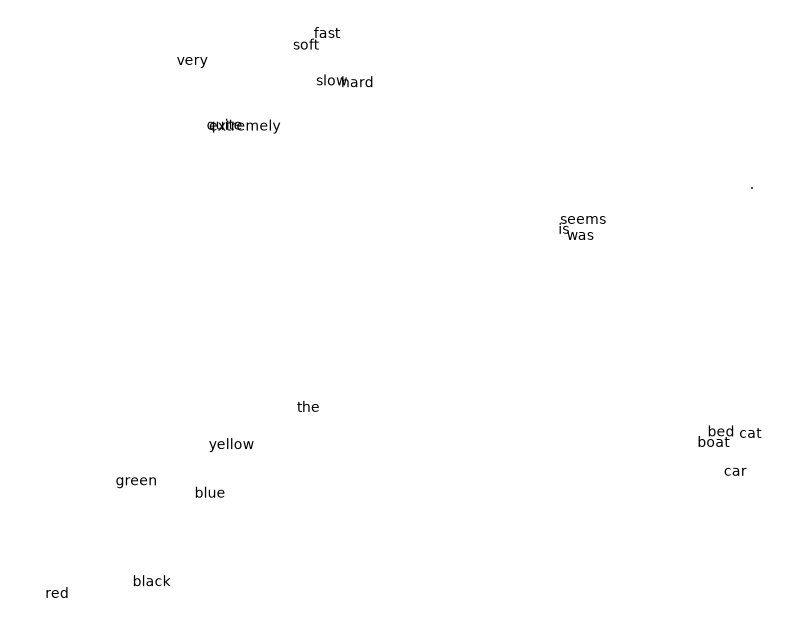

In [39]:
import numpy as np

# Centrowanie danych wokół średniej
X = np.array(embedding.embeddings)
X_centered = X - np.mean(X, axis=0)

# SVD: X_centered = U * S * Vt
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

# Rzut na 2 pierwsze składowe główne (odpowiednik transformed)
transformed = X_centered @ Vt[:2].T

import matplotlib.pyplot as plt

# 1. Konwersja wektorów na macierz NumPy (jeśli są listą list lub własnym typem Tensor)
embeddings_matrix = np.array(embedding.embeddings)

# 3. Wykres punktowy (indeksowanie wycinkami NumPy zamiast *zip(*transformed))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(transformed[:, 0], transformed[:, 1], marker='.', color='w')

# 4. Naniesienie etykiet tekstowych
for word, idx in vocab.w2i.items():
    ax.annotate(word, (transformed[idx, 0], transformed[idx, 1]))

# 5. Wbudowane, czyste ukrycie obu osi na raz
ax.axis('off')
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ (None, 10)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │           242 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462 (1.80 KB)

 Trainable params: 462 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

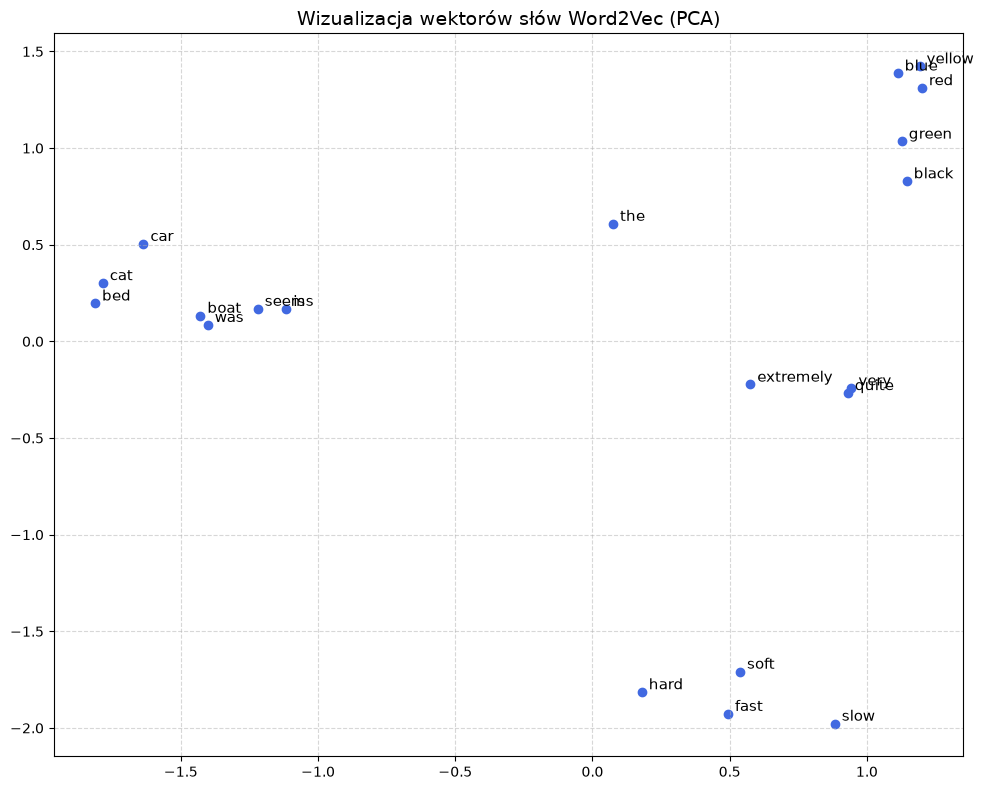

In [55]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
import tensorflow as tf

max_tokens = 5000
embedding_dim = 10  # wymiar wektora słowa

vectorize_layer = tf.keras.layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    standardize="lower_and_strip_punctuation",
    split="whitespace",
)


vectorize_layer.adapt(sentences)
vocab = vectorize_layer.get_vocabulary()
vocab_size = len(vocab)


sequences = vectorize_layer(sentences).numpy()


window_size = 2  # szerokość okna kontekstu w lewo i prawo
pairs = []

for seq in sequences:
    # Odrzucamy tokeny paddingu (indeks 0) i słowa nieznane (indeks 1)
    clean_seq = [token for token in seq if token > 1]
    n = len(clean_seq)

    for i, target_word in enumerate(clean_seq):
        start = max(0, i - window_size)
        end = min(n, i + window_size + 1)
        for j in range(start, end):
            if i != j:
                pairs.append((target_word, clean_seq[j]))

pairs = np.array(pairs)
x_train = pairs[:, 0]  # słowa wejściowe (target)
y_train = pairs[:, 1]  # słowa kontekstowe do przewidzenia (context)

model = tf.keras.Sequential([
    # Warstwa wejściowa przyjmuje pojedynczy indeks (skalar)
    tf.keras.layers.Input(shape=()),
    # Warstwa osadzeń – lookup table o wymiarach (vocab_size x embedding_dim)
    tf.keras.layers.Embedding(
        input_dim=vocab_size, output_dim=embedding_dim, name="word_embedding"
    ),
    # Rzutowanie na cały słownik + Softmax (predykcja słowa z otoczenia)
    tf.keras.layers.Dense(units=vocab_size, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

model.summary()

# Trenowanie modelu
model.fit(x_train, y_train, epochs=200, batch_size=32, verbose=0)


embedding_layer = model.get_layer("word_embedding")
embeddings_matrix = (
    embedding_layer.get_weights()[0]
)  # macierz (vocab_size, embedding_dim)


words_to_plot = vocab[2:]
vectors_to_plot = embeddings_matrix[2:]

# Redukcja wymiarowości do 2 składowych
pca = PCA(n_components=2)
transformed = pca.fit_transform(vectors_to_plot)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(transformed[:, 0], transformed[:, 1], marker="o", color="royalblue")

# Podpisanie każdego punktu odpowiednim słowem
for i, word in enumerate(words_to_plot):
    ax.annotate(
        word,
        (transformed[i, 0], transformed[i, 1]),
        fontsize=11,
        xytext=(5, 2),
        textcoords="offset points",
    )

ax.grid(True, linestyle="--", alpha=0.5)
ax.set_title("Wizualizacja wektorów słów Word2Vec (PCA)", fontsize=14)

plt.tight_layout()
plt.show()

Kształt wektora y: (22,)
Suma prawdopodobieństw: 1.0
the


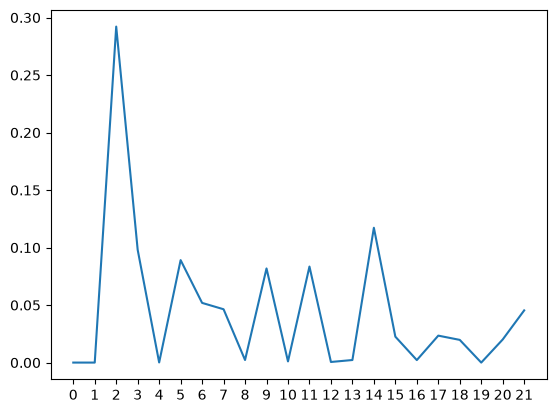

In [62]:
word = "cat"

word_idx = vocab.index(word)
y_probs = model.predict(np.array([word_idx]), verbose=0)[0]

print("Kształt wektora y:", y_probs.shape)
plt.plot(y_probs)
plt.xticks(np.arange(0,len(y_probs), 1))
print("Suma prawdopodobieństw:", np.sum(y_probs))
print(vocab[np.argmax(y_probs)])